In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
np.random.seed(0)

In [3]:
movie = np.zeros((2_000, 9, 2))

In [4]:
data, truth = generate_data(
    n_timepoints=1_000,
    n_components=2,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0
)

In [5]:
data.shape

(2, 2000)

In [6]:
movie.shape

(2000, 9, 2)

In [7]:
movie[:, :, 0].shape

(2000, 9)

In [8]:
factor = 4

movie[:, 0:3] = data[0, None, None].T
movie[:, 3:6] = data[1, None, None].T * factor
movie[:, 6:] = data[0, None, None].T + (data[1, None, None].T * factor)

In [9]:
t, xdim, ydim = movie.shape

In [10]:
series = movie.reshape(t, xdim * ydim).T

In [11]:
series += np.vstack([np.random.normal(scale=10, size=2_000) for i in range(18)])

In [12]:
series.shape

(18, 2000)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='500px', css_width='700px')
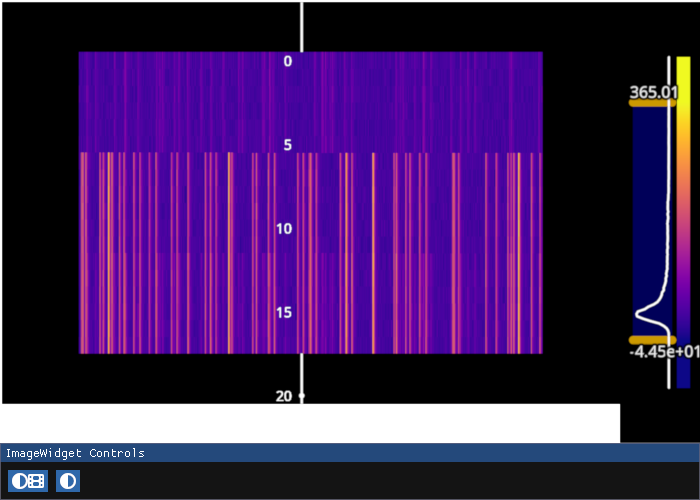

In [13]:
iw_series = fpl.ImageWidget(series, figure_kwargs={"size": (700, 500)})
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [14]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|██████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 24640.17it/s]


(18, 2000)
(144, 1984)


100%|██████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 15376.27it/s]

computing H
Computing Hp
computimng svd of Hp


RFBOutputContext()

JupyterWgpuCanvas()
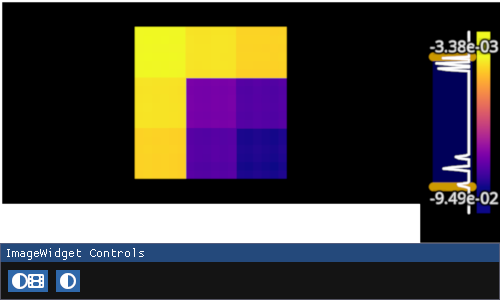

In [15]:
iw_adj = fpl.ImageWidget(st_svd.adjacency)
iw_adj.show()

best: k = n_components + 1

1) few bg pixels, real components cluster compactly, bg points are scattered
2) lots of bg pixels, bg points compact, real components less compact

In [16]:
clustering = ClusteringCPQR(st_svd.adjacency, k=2)

In [17]:
clustering.Qk.shape

(18, 2)

In [18]:
clustering.W.shape

(2, 2)

In [19]:
clustering.transformed.shape

(2, 18)

In [20]:
import pygfx
from wgpu.gui.jupyter import WgpuCanvas

canvas = WgpuCanvas()
renderer = pygfx.WgpuRenderer(target=canvas, blend_mode="weighted_plus")

fig = fpl.Figure(
    cameras="3d", 
    controller_types="orbit", 
    size=(1000, 800),
    renderer=renderer,
    canvas=canvas
)

subplot = fig[0, 0]

subplot.add_scatter(clustering.Qk, colors="r", name="Qk", sizes=15, alpha=0.2)
# overlapping pixels in pink
subplot["Qk"].colors[12:] = (1, 0.2, 0.5, 0.4)
subplot.add_scatter(clustering.W.T, colors="b", name="W", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15, alpha=0.2)


fig[0, 0].axes.intersection = (0, 0, 0)
fig.canvas.quality = 100
fig.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


In [21]:
from fastplotlib.graphics._axes import Axes

In [22]:
if clustering.k == 2:
    basis_W = np.array([
        [*clustering.W.T[0], 0],
        [*clustering.W.T[1], 0],
        [0., 0., 1.]
    ])

elif clustering.k == 3:
    basis_W = np.array([
        clustering.W.T[0],
        clustering.W.T[1],
        clustering.W.T[2]
    ])

axes_W = Axes(fig[0, 0], intersection=(0, 0, 0), basis=basis_W)
axes_W.colors = ("b", "b", "b")

fig[0, 0].scene.add(axes_W.world_object)
fig[0, 0].add_animations(axes_W.update_using_camera)

fig[0, 0].axes.colors = ("g", "g", "g")

In [23]:
clustering.transformed.argmax(axis=0)

array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1])

In [24]:
from ipywidgets import VBox

In [25]:
iw_movie = fpl.ImageWidget(series, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.Qk, clustering.W, clustering.transformed.T], 
    names=["Qk", "W", "transform"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.figure["transform"].set_title("W.T x Qk.T")
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

iw_movie.figure[0, 0].add_image(
    data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
    cmap="tab20",
    offset=(-45, 0, 0),
    name="cluster-labels"
)
iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.Qk, clustering.W, clustering.transformed.T])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

    iw_movie.figure[0, 0].delete_graphic(iw_movie.figure[0, 0]["cluster-labels"])
    
    iw_movie.figure[0, 0].add_image(
        data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
        cmap="tab20",
        offset=(-45, 0, 0),
        name="cluster-labels"
    )
    iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

VBox([iw_movie.show(), iw.show()])

RFBOutputContext()

RFBOutputContext()

In [26]:
selector_movie = iw_movie.managed_graphics[0].add_linear_selector(axis="y")
selector_Qk = iw.figure["Qk"]["image_widget_managed"].add_linear_selector(axis="y")
selector_transform = iw.figure["transform"]["image_widget_managed"].add_linear_selector(axis="y")
selectors = [selector_movie, selector_Qk, selector_transform]

In [27]:
class IndexStore:
    def __init__(self):
        self.index: int = None

    def set_index(self, new_index: int, source_graphic: fpl.LinearSelector | fpl.ScatterGraphic):
        self._set_points(new_index)
        self._set_linear_selectors(new_index, source_graphic)

    def _set_points(self, index: int):
        # reset colors
        subplot["Qk"].colors = (1, 0, 0, 0.2)
        subplot["Qk"].sizes = 15
        
        subplot["transform"].colors = (0, 1, 0, 0.2)
        subplot["transform"].sizes = 15
        
        # set colors and size
        subplot["Qk"].colors[index] = "yellow"
        subplot["Qk"].sizes[index] = 25
        
        subplot["transform"].colors[index] = "cyan"
        subplot["transform"].sizes[index] = 25

    def _set_linear_selectors(self, index: int, source_graphic):
        with fpl.pause_events(*selectors):
            for selector in selectors:
                if source_graphic is selector:
                    continue
                selector.selection = index

    def _scatter_callback(self, ev):
        index = ev.pick_info["vertex_index"]
        self.set_index(index, ev.graphic)
    
    def register_scatter(self, graphic: fpl.ScatterGraphic):
        graphic.add_event_handler(self._scatter_callback, "click")

    def _linear_selector_callback(self, ev):
        index = ev.get_selected_index()
        self.set_index(index, ev.graphic)
    
    def register_linear_selector(self, selector: fpl.LinearSelector):
        selector.add_event_handler(self._linear_selector_callback, "selection")

In [28]:
index_store = IndexStore()

index_store.register_scatter(subplot["Qk"])
index_store.register_scatter(subplot["transform"])

index_store.register_linear_selector(selector_movie)
index_store.register_linear_selector(selector_Qk)
index_store.register_linear_selector(selector_transform)

In [29]:
clustering.Qk

array([[-0.99445281, -0.10518368],
       [-0.99433451, -0.1062962 ],
       [-0.9948272 , -0.10158174],
       [-0.99423103, -0.10725978],
       [-0.99490636, -0.10080349],
       [-0.99426376, -0.10695591],
       [ 0.59557208, -0.80330187],
       [ 0.5481766 , -0.83636261],
       [ 0.57165975, -0.82049079],
       [ 0.62354377, -0.78178844],
       [ 0.60821366, -0.79377336],
       [ 0.58123977, -0.81373234],
       [-0.39673082, -0.917935  ],
       [-0.39981878, -0.91659421],
       [-0.38156586, -0.92434166],
       [-0.43820054, -0.89887724],
       [-0.42821759, -0.90367566],
       [-0.40660105, -0.91360582]])

In [30]:
clustering.Qk[:6]

clustering.Qk[6:12]

array([[ 0.59557208, -0.80330187],
       [ 0.5481766 , -0.83636261],
       [ 0.57165975, -0.82049079],
       [ 0.62354377, -0.78178844],
       [ 0.60821366, -0.79377336],
       [ 0.58123977, -0.81373234]])

In [31]:
a = clustering.Qk[0]

b = clustering.Qk[10]

c = clustering.Qk[-1]

np.column_stack([a.T, b.T, c.T])

array([[-0.99445281,  0.60821366, -0.40660105],
       [-0.10518368, -0.79377336, -0.91360582]])

In [32]:
a = np.column_stack([a.T, b.T])
np.linalg.solve(a, c)

array([1.02938125, 1.01456128])

In [33]:
import scipy

In [34]:
idx, proj = scipy.linalg.interpolative.interp_decomp(clustering.Qk.T, eps_or_k=2)

In [35]:
idx

array([ 8,  3,  2,  1,  4,  5,  6,  7,  0,  9, 10, 11, 12, 13, 14, 15, 16,
       17], dtype=int32)

In [36]:
proj.shape

(2, 16)

In [37]:
np.round(proj)

array([[-0., -0., -0., -0.,  1.,  1., -0.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.],
       [ 1.,  1.,  1.,  1., -0.,  0.,  1., -0., -0., -0.,  1.,  1.,  1.,
         1.,  1.,  1.]])

In [38]:
proj

array([[-6.50940650e-03, -1.10495087e-03, -7.40129218e-03,
        -3.48465651e-04,  9.83439331e-01,  1.01512013e+00,
        -2.38054685e-03,  9.62472923e-01,  9.74183996e-01,
         9.93510346e-01,  9.92033391e-01,  9.90135870e-01,
         1.00115040e+00,  9.65358490e-01,  9.72018714e-01,
         9.85918871e-01],
       [ 9.96856868e-01,  9.99468760e-01,  9.96423674e-01,
         9.99832566e-01, -3.35730856e-02,  3.23131317e-02,
         9.98854310e-01, -7.37622735e-02, -5.16096166e-02,
        -1.33670120e-02,  9.69428985e-01,  9.71443830e-01,
         9.59418100e-01,  9.95801883e-01,  9.89590486e-01,
         9.75840778e-01]])

RFBOutputContext()

JupyterWgpuCanvas()
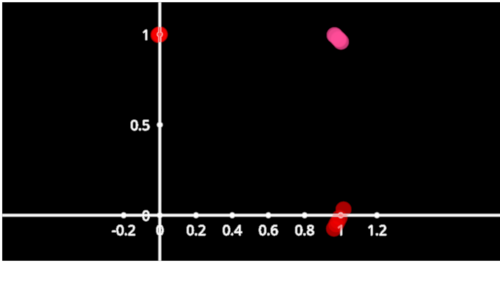

In [72]:
fig_proj = fpl.Figure()
fig_proj[0, 0].add_scatter(proj.T, sizes=15, colors="r", alpha=0.4)

# rows 12 onward are overlapped pixels
fig_proj[0, 0].graphics[0].colors[idx[2:] > 12] = (1, 0.3, 0.6, 0.6)

fig_proj[0, 0].axes.intersection = (0, 0, 0)
fig_proj.show()

In [73]:
rounded_proj = np.round(proj)
rounded_proj.T

array([[-0.,  1.],
       [-0.,  1.],
       [-0.,  1.],
       [-0.,  1.],
       [ 1., -0.],
       [ 1.,  0.],
       [-0.,  1.],
       [ 1., -0.],
       [ 1., -0.],
       [ 1., -0.],
       [ 1.,  1.],
       [ 1.,  1.],
       [ 1.,  1.],
       [ 1.,  1.],
       [ 1.,  1.],
       [ 1.,  1.]])

In [74]:
basis = np.unique(rounded_proj.T, axis=0)

In [75]:
basis

array([[-0.,  1.],
       [ 1., -0.],
       [ 1.,  1.]])

In [46]:
basis[0] = basis[0] + basis[-1]
basis

array([[ 1.,  2.],
       [ 1., -0.],
       [ 1.,  1.]])

In [196]:
basis[1] = basis[1] + basis[-1]

In [197]:
basis

array([[ 0.,  1.],
       [ 1.,  1.],
       [ 1., -0.]])